# 16 · Project: analyze a month of store sales

**Level:** Capstone · **Practice time:** 60–90 minutes

[← Previous](15_signal_processing_with_fft.ipynb) · [Course guide](../README.md) · [Next →](17_project_pca_and_clustering.ipynb)

**You will learn:** Combine cleaning, broadcasting, aggregation, plots, and business interpretation.

**Prerequisites:** Notebooks 00–09; revisit 11–13 for memory and accuracy.

## How to learn with this notebook

1. Run cells from top to bottom. Predict results before executing each example.
2. Do the **Try it** experiment by editing the example or adding a cell below it.
3. Replace `None` in each exercise with your answer, then rerun its check cell.
4. Consult the solutions at the end only after trying. An untouched exercise prints **Pending**, so Run All succeeds without claiming you solved it.
5. Complete the independent challenge, then restart the kernel and run all cells again.

Each notebook imports its own dependencies and creates its own data. You do not need variables from another notebook. The supplied outputs show a verified reference run; rerun cells to explore your changes.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)

NumPy version: 2.5.3


## Step 1 · Project brief and reproducible data

You manage three stores selling four products over 30 days. Build a report of revenue per store, top products, and daily trends. Quantities have shape **(day, store, product)**. This dataset is synthetic, and prices are fixed for the exercise. Treat a NaN as an unavailable count, not as zero sales.

Before running each stage, sketch the expected output shape. The worked pipeline is a model; the exercises ask you to extend it.

In [2]:
rng = np.random.default_rng(2026)
stores = np.array(["North", "Central", "South"])
products = np.array(["Tea", "Coffee", "Juice", "Water"])
prices = np.array([20., 40., 35., 15.])
units = rng.poisson(lam=np.array([12, 8, 6, 15]), size=(30, 3, 4)).astype(float)
units[2, 0, 1] = np.nan
units[10, 2, 3] = np.nan
print("Shape:", units.shape, "missing:", np.isnan(units).sum())
assert units.shape == (30, 3, 4)

Shape: (30, 3, 4) missing: 2


**Try it:** Add a fifth product and update the rate vector and prices consistently.

## Step 2 · Clean and calculate revenue

Fill a missing count with that store/product pair’s average observed count across days. This gives fractional estimated counts, so report them as estimates. Keep the original array and missing mask for auditing. Broadcasting aligns the price vector with the last axis.

In [3]:
missing = np.isnan(units)
if np.any(missing.all(axis=0)):
    raise ValueError("A store/product pair has no observed counts")
mean_units = np.nanmean(units, axis=0, keepdims=True)
filled_units = np.where(missing, mean_units, units)
revenue = filled_units * prices
store_revenue = revenue.sum(axis=(0, 2))
product_revenue = revenue.sum(axis=(0, 1))
daily_revenue = revenue.sum(axis=(1, 2))
print("Revenue by store:", dict(zip(stores, store_revenue.round(2))))
print("Top product:", products[product_revenue.argmax()])
print("Revenue from imputed entries:", revenue[missing].sum().round(2))
assert np.isfinite(revenue).all()
np.testing.assert_allclose(store_revenue.sum(), daily_revenue.sum())
np.testing.assert_allclose(product_revenue.sum(), revenue.sum())

Revenue by store: {np.str_('North'): np.float64(31487.76), np.str_('Central'): np.float64(30220.0), np.str_('South'): np.float64(29411.9)}
Top product: Coffee
Revenue from imputed entries: 584.66


**Try it:** Compare the total against dropping only missing entries with nansum(units * prices). Explain the difference.

## Step 3 · Visualize and interpret

A line chart shows daily change; bars compare totals across stores. A rolling mean smooths short-term variation but omits the initial incomplete windows here. Label every chart with units and keep interpretation separate from what synthetic data can establish.

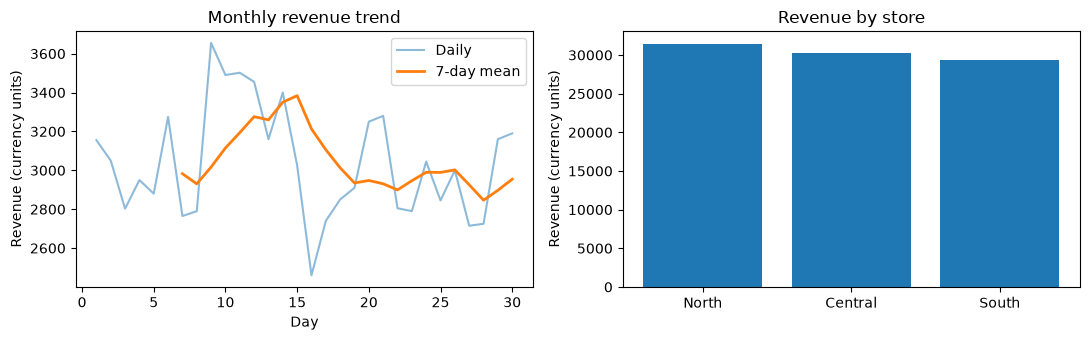

Best day: 9
Estimated total revenue: 91119.66


In [4]:
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
weekly_trend = sliding_window_view(daily_revenue, 7).mean(axis=-1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(np.arange(1, 31), daily_revenue, alpha=0.5, label="Daily")
axes[0].plot(np.arange(7, 31), weekly_trend, linewidth=2, label="7-day mean")
axes[0].set(xlabel="Day", ylabel="Revenue (currency units)", title="Monthly revenue trend")
axes[0].legend()
axes[1].bar(stores, store_revenue)
axes[1].set(ylabel="Revenue (currency units)", title="Revenue by store")
plt.tight_layout()
plt.show()
print("Best day:", daily_revenue.argmax() + 1)
print("Estimated total revenue:", round(revenue.sum(), 2))

**Try it:** Write three findings using numbers and one limitation caused by missing data.

## Your practice exercises

Use the named answer variables. The checks verify your result; they do not require the same approach as the reference solution. If an assertion fails, read the expected value and inspect your shape and dtype.

### Exercise 1

Compute each store’s fraction of total revenue, in store order.

In [5]:
store_share = None  # TODO: replace None with your answer

In [6]:
if store_share is None:
    print("Pending: complete Exercise 1 first.")
else:
    assert store_share.shape == (3,)
    np.testing.assert_allclose(store_share.sum(), 1)
    np.testing.assert_allclose(store_share, store_revenue / revenue.sum())
    print("Exercise 1 passed!")

Pending: complete Exercise 1 first.


### Exercise 2

Compute average DAILY revenue by store and product, shape (3, 4).

In [7]:
average_daily = None  # TODO: replace None with your answer

In [8]:
if average_daily is None:
    print("Pending: complete Exercise 2 first.")
else:
    assert average_daily.shape == (3, 4)
    np.testing.assert_allclose(average_daily * 30, revenue.sum(axis=0))
    print("Exercise 2 passed!")

Pending: complete Exercise 2 first.


## Independent challenge

Independent deliverable: create a report cell with total revenue, best store, best product, missing count, and imputed revenue share. Export the cleaned data and summary arrays to .npz, reload them, and verify equality. Add a scenario where Coffee price rises 10% with fixed units; label the fixed-demand assumption. Success means correct shapes, reconciled totals, labeled plots, and a clear explanation of the cleaning policy.

Add code and explanation cells below. Decide on expected results before checking your implementation.

In [9]:
# Your independent challenge work goes here.

## Before you move on

- Explain the main idea in your own words without reading the examples.
- Make both exercise checks print **passed**.
- Try at least one changed input or edge case and explain the result.
- Finish the independent challenge or write down a specific question to revisit.

Expertise comes from repeated practice and debugging unfamiliar problems. Completing these notebooks gives you a broad practical foundation, not a substitute for that experience.

---

## Reference solutions — try first

These cells use separate reference variables, so they do not fill in your exercise answers. They also check the reference result. Compare your reasoning as well as the output.

### Solution 1

Compute each store’s fraction of total revenue, in store order.

**Why it works:** Dividing every store total by the overall total produces fractions that sum to one.

In [10]:
reference_store_share = store_revenue / revenue.sum()
assert reference_store_share.shape == (3,)
np.testing.assert_allclose(reference_store_share.sum(), 1)
np.testing.assert_allclose(reference_store_share, store_revenue / revenue.sum())
print(reference_store_share)

[0.3456 0.3317 0.3228]


### Solution 2

Compute average DAILY revenue by store and product, shape (3, 4).

**Why it works:** A mean over the day axis leaves store and product axes. Multiplying by 30 recovers their monthly totals.

In [11]:
reference_average_daily = revenue.mean(axis=0)
assert reference_average_daily.shape == (3, 4)
np.testing.assert_allclose(reference_average_daily * 30, revenue.sum(axis=0))
print(reference_average_daily)

[[233.3333 362.7586 220.5    233.    ]
 [260.     320.     191.3333 236.    ]
 [224.     337.3333 197.1667 221.8966]]


## Continue learning

- [Official NumPy documentation: routines.statistics ](https://numpy.org/doc/stable/reference/routines.statistics.html)
- [Official NumPy documentation: numpy.savez_compressed ](https://numpy.org/doc/stable/reference/generated/numpy.savez_compressed.html)

[Next →](17_project_pca_and_clustering.ipynb)